In [1]:

!pip install -q torch matplotlib


In [2]:

import os
import sys
import time
import shutil
import subprocess
import platform

from pathlib import Path

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from matplotlib.patches import FancyBboxPatch

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

print("=" * 60)
print("CREATING VISIONPORT PROJECT REPOSITORY")
print("=" * 60)

PROJECT_DIR = Path("/content/VisionPort")

if PROJECT_DIR.exists():
    shutil.rmtree(PROJECT_DIR)

PROJECT_DIR.mkdir(parents=True)

folders = [
    "app",
    "models",
    "inference",
    "preprocessing",
    "tests",
    "outputs",
    "docs"
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(exist_ok=True)

print("Project repository created successfully!")

for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(str(PROJECT_DIR), "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")


CREATING VISIONPORT PROJECT REPOSITORY
Project repository created successfully!
VisionPort/
  models/
  docs/
  tests/
  preprocessing/
  inference/
  app/
  outputs/


In [4]:

readme = """
# VisionPort - Deep Learning Inference Platform

## Description
VisionPort is an end-to-end deep learning inference platform.

## Architecture
Client -> FastAPI -> Preprocessing -> Triton/TensorRT
-> PyTorch Model -> GPU -> Prediction Response

## Technologies
- Python
- PyTorch
- CUDA
- FastAPI
- NVIDIA GPU
- Git and GitHub
"""

model_code = '''
import torch
import torch.nn as nn

class VisionPortCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Linear(32, 10)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)
'''

(PROJECT_DIR / "README.md").write_text(readme)

(PROJECT_DIR / "models" / "model.py").write_text(model_code)

(PROJECT_DIR / "requirements.txt").write_text(
    "torch\\nmatplotlib\\nfastapi\\n"
)

(PROJECT_DIR / ".gitignore").write_text(
    "__pycache__/\\n*.pyc\\n.env\\noutputs/*.pt\\n"
)

print("Project files created successfully!")


Project files created successfully!


In [5]:

def git(command):

    result = subprocess.run(
        ["git"] + command,
        cwd=PROJECT_DIR,
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        raise RuntimeError(result.stderr)

    return result.stdout.strip()

subprocess.run([
    "git", "config", "--global",
    "user.name", "VisionPort Student"
], check=True)

subprocess.run([
    "git", "config", "--global",
    "user.email", "student@example.com"
], check=True)

git(["init", "-b", "main"])

git(["add", "."])

git(["commit", "-m", "Initial VisionPort project setup"])

print("Git repository initialized successfully!")

print(git(["log", "--oneline"]))


Git repository initialized successfully!
5123ada Initial VisionPort project setup


In [6]:

git(["switch", "-c", "feature/environment-setup"])

environment_info = """
VisionPort Development Environment
Framework: PyTorch
Hardware: CPU/CUDA GPU
Version Control: Git
"""

(PROJECT_DIR / "docs" / "environment.txt").write_text(
    environment_info
)

git(["add", "."])

git(["commit", "-m", "Add development environment documentation"])

print("Feature branch created successfully!")

print("Git History:")
print(git(["log", "--oneline"]))


Feature branch created successfully!
Git History:
67e4366 Add development environment documentation
5123ada Initial VisionPort project setup


In [7]:

git(["switch", "main"])

git([
    "merge",
    "--no-ff",
    "feature/environment-setup",
    "-m",
    "Merge environment setup"
])

print("Feature branch merged successfully!")

print("\nGit Branches:")
print(git(["branch"]))

print("\nGit History:")
print(git(["log", "--oneline", "--graph", "--all"]))


Feature branch merged successfully!

Git Branches:
feature/environment-setup
* main

Git History:
*   77e5678 Merge environment setup
|\  
| * 67e4366 Add development environment documentation
|/  
* 5123ada Initial VisionPort project setup


In [8]:

print("=" * 60)
print("PYTORCH AND CUDA ENVIRONMENT")
print("=" * 60)

print("Python Version:", sys.version.split()[0])
print("Operating System:", platform.system())
print("PyTorch Version:", torch.__version__)

gpu_available = torch.cuda.is_available()

print("CUDA Available:", gpu_available)

if gpu_available:

    device = torch.device("cuda")

    print("GPU Name:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
    print("GPU Count:", torch.cuda.device_count())

    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3), 2
        ),
        "GB"
    )

else:

    device = torch.device("cpu")

    print("GPU not available. Using CPU.")

print("Selected Device:", device)


PYTORCH AND CUDA ENVIRONMENT
Python Version: 3.13.18
Operating System: Linux
PyTorch Version: 2.14.1+cpu
CUDA Available: False
GPU not available. Using CPU.
Selected Device: cpu


In [9]:

class VisionPortCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Linear(32, 10)

    def forward(self, x):

        x = self.features(x)

        x = torch.flatten(x, 1)

        return self.classifier(x)


model = VisionPortCNN().to(device)

model.eval()

print("VisionPort CNN model created successfully!")


VisionPort CNN model created successfully!


In [10]:

sample_input = torch.randn(8, 3, 64, 64).to(device)

with torch.no_grad():

    prediction = model(sample_input)

print("Model:", model.__class__.__name__)

print("Input Shape:", tuple(sample_input.shape))

print("Output Shape:", tuple(prediction.shape))

print(
    "Number of Parameters:",
    sum(p.numel() for p in model.parameters())
)

predicted_classes = torch.argmax(prediction, dim=1)

print("Predicted Classes:", predicted_classes.cpu().tolist())


Model: VisionPortCNN
Input Shape: (8, 3, 64, 64)
Output Shape: (8, 10)
Number of Parameters: 5418
Predicted Classes: [1, 1, 1, 1, 1, 1, 1, 1]


In [11]:

model_path = PROJECT_DIR / "outputs" / "visionport_model.pth"

torch.save(model.state_dict(), model_path)

print("Model saved successfully!")
print("Saved Location:", model_path)


Model saved successfully!
Saved Location: /content/VisionPort/outputs/visionport_model.pth


In [ ]:

def benchmark(device, iterations=20):

    benchmark_model = VisionPortCNN().to(device)

    benchmark_model.eval()

    data = torch.randn(8, 3, 64, 64).to(device)

    with torch.no_grad():

        for _ in range(5):
            benchmark_model(data)

        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        for _ in range(iterations):
            benchmark_model(data)

        if device.type == "cuda":
            torch.cuda.synchronize()

        end = time.perf_counter()

    return ((end - start) / iterations) * 1000


cpu_time = benchmark(torch.device("cpu"))

times = {"CPU": cpu_time}

print("CPU Average Time:", round(cpu_time, 4), "ms")

if gpu_available:

    gpu_time = benchmark(torch.device("cuda"))

    times["CUDA GPU"] = gpu_time

    print("GPU Average Time:", round(gpu_time, 4), "ms")

    print("Speedup:", round(cpu_time / gpu_time, 2), "x")

else:

    print("CUDA benchmark skipped because GPU is unavailable.")


In [12]:

def benchmark(device, iterations=20):

    benchmark_model = VisionPortCNN().to(device)

    benchmark_model.eval()

    data = torch.randn(8, 3, 64, 64).to(device)

    with torch.no_grad():

        for _ in range(5):
            benchmark_model(data)

        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        for _ in range(iterations):
            benchmark_model(data)

        if device.type == "cuda":
            torch.cuda.synchronize()

        end = time.perf_counter()

    return ((end - start) / iterations) * 1000


cpu_time = benchmark(torch.device("cpu"))

times = {"CPU": cpu_time}

print("CPU Average Time:", round(cpu_time, 4), "ms")

if gpu_available:

    gpu_time = benchmark(torch.device("cuda"))

    times["CUDA GPU"] = gpu_time

    print("GPU Average Time:", round(gpu_time, 4), "ms")

    print("Speedup:", round(cpu_time / gpu_time, 2), "x")

else:

    print("CUDA benchmark skipped because GPU is unavailable.")


CPU Average Time: 14.8602 ms
CUDA benchmark skipped because GPU is unavailable.


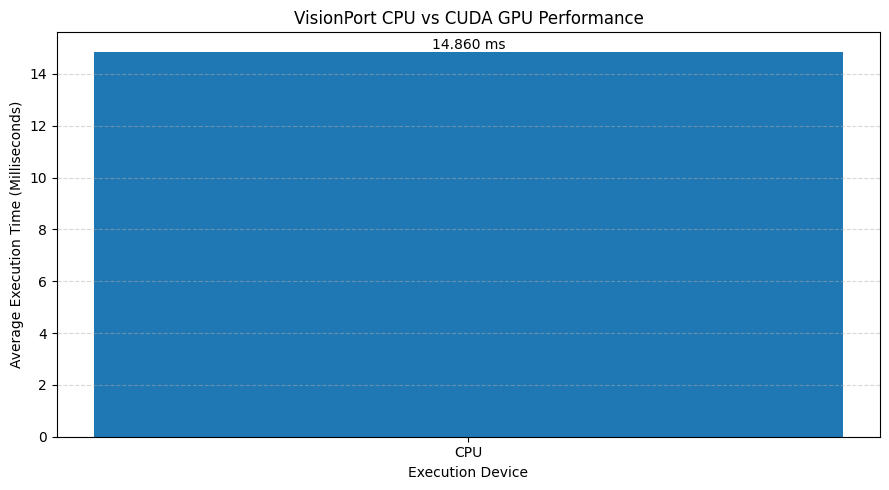

In [13]:

plt.figure(figsize=(9, 5))

bars = plt.bar(
    list(times.keys()),
    list(times.values())
)

plt.title("VisionPort CPU vs CUDA GPU Performance")

plt.xlabel("Execution Device")

plt.ylabel("Average Execution Time (Milliseconds)")

plt.grid(axis="y", linestyle="--", alpha=0.5)

for bar, value in zip(bars, times.values()):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f} ms",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.show()


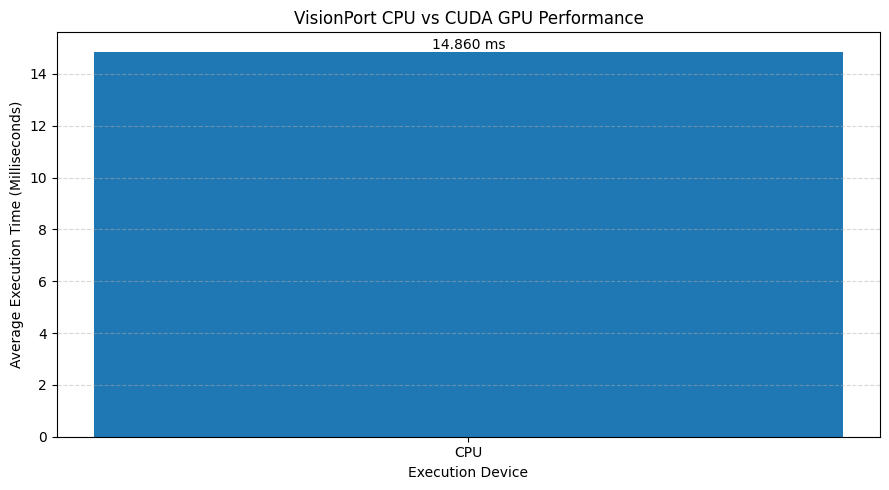

In [14]:

plt.figure(figsize=(9, 5))

bars = plt.bar(
    list(times.keys()),
    list(times.values())
)

plt.title("VisionPort CPU vs CUDA GPU Performance")

plt.xlabel("Execution Device")

plt.ylabel("Average Execution Time (Milliseconds)")

plt.grid(axis="y", linestyle="--", alpha=0.5)

for bar, value in zip(bars, times.values()):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f} ms",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.show()


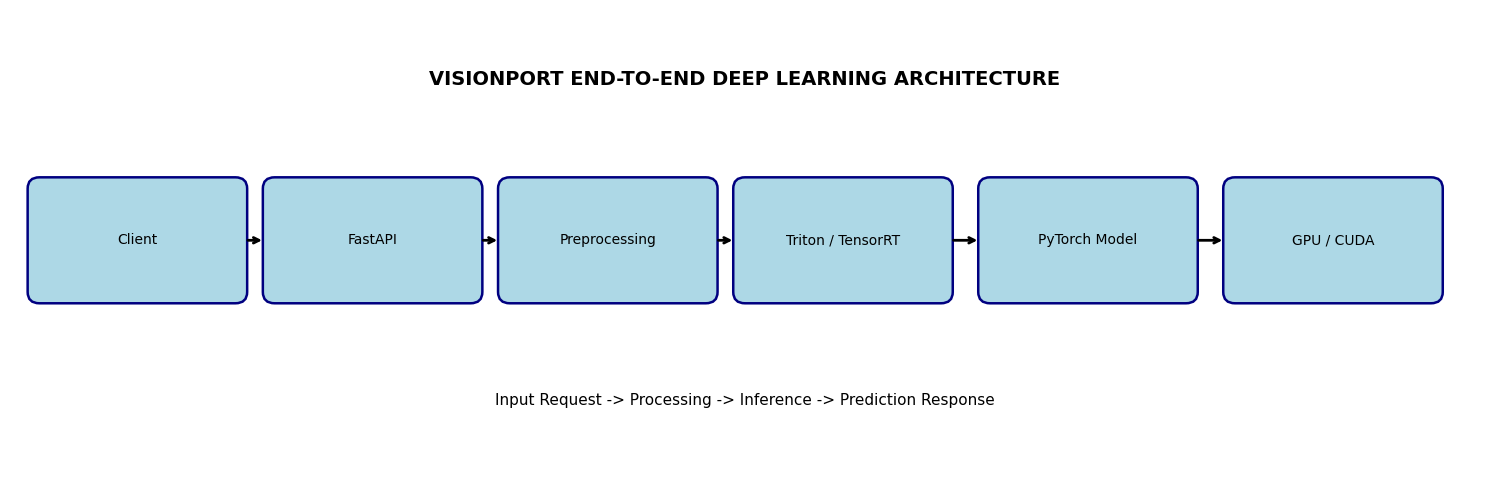

In [15]:

fig, ax = plt.subplots(figsize=(15, 5))

ax.set_xlim(0, 15)
ax.set_ylim(0, 5)

ax.axis("off")

architecture = [
    ("Client", 0.3),
    ("FastAPI", 2.7),
    ("Preprocessing", 5.1),
    ("Triton / TensorRT", 7.5),
    ("PyTorch Model", 10.0),
    ("GPU / CUDA", 12.5)
]

for label, x in architecture:

    box = FancyBboxPatch(
        (x, 2),
        2,
        1.1,
        boxstyle="round,pad=0.12",
        linewidth=1.8,
        edgecolor="navy",
        facecolor="lightblue"
    )

    ax.add_patch(box)

    ax.text(
        x + 1,
        2.55,
        label,
        ha="center",
        va="center",
        fontsize=10
    )

for i in range(len(architecture) - 1):

    x1 = architecture[i][1] + 2
    x2 = architecture[i + 1][1]

    ax.annotate(
        "",
        xy=(x2 - 0.1, 2.55),
        xytext=(x1 + 0.1, 2.55),
        arrowprops=dict(arrowstyle="->", lw=2)
    )

ax.text(
    7.5,
    4.2,
    "VISIONPORT END-TO-END DEEP LEARNING ARCHITECTURE",
    ha="center",
    fontsize=14,
    fontweight="bold"
)

ax.text(
    7.5,
    0.8,
    "Input Request -> Processing -> Inference -> Prediction Response",
    ha="center",
    fontsize=11
)

plt.tight_layout()

plt.show()


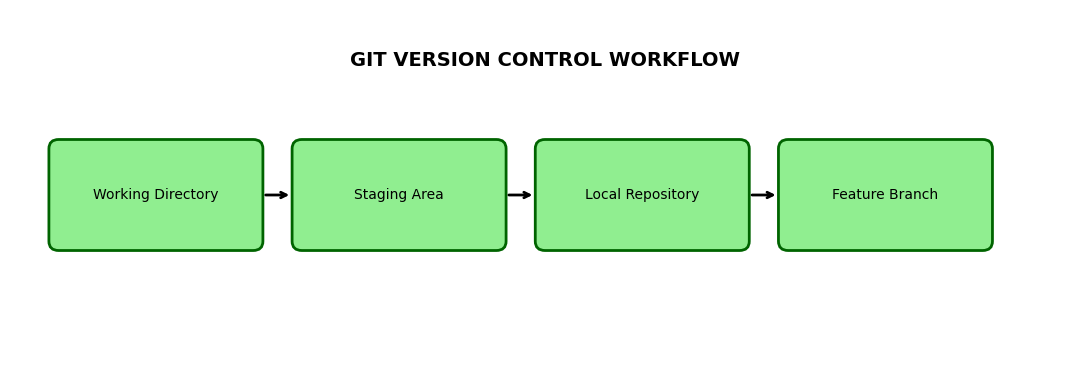

In [16]:

fig, ax = plt.subplots(figsize=(11, 4))

ax.set_xlim(0, 11)
ax.set_ylim(0, 4)

ax.axis("off")

git_steps = [
    ("Working Directory", 0.5),
    ("Staging Area", 3.0),
    ("Local Repository", 5.5),
    ("Feature Branch", 8.0)
]

for label, x in git_steps:

    box = FancyBboxPatch(
        (x, 1.5),
        2,
        1,
        boxstyle="round,pad=0.1",
        facecolor="lightgreen",
        edgecolor="darkgreen",
        linewidth=2
    )

    ax.add_patch(box)

    ax.text(
        x + 1,
        2,
        label,
        ha="center",
        va="center",
        fontsize=10
    )

for i in range(3):

    ax.annotate(
        "",
        xy=(git_steps[i + 1][1] - 0.1, 2),
        xytext=(git_steps[i][1] + 2.1, 2),
        arrowprops=dict(arrowstyle="->", lw=2)
    )

ax.text(
    5.5,
    3.4,
    "GIT VERSION CONTROL WORKFLOW",
    ha="center",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()


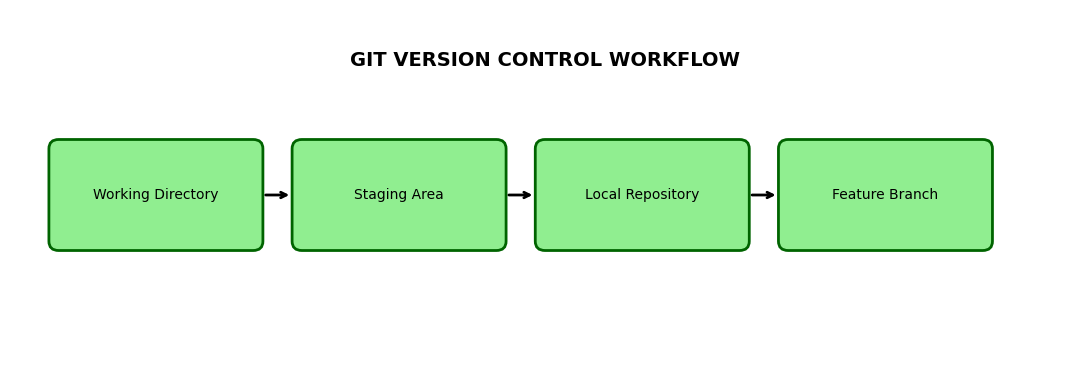

In [17]:

fig, ax = plt.subplots(figsize=(11, 4))

ax.set_xlim(0, 11)
ax.set_ylim(0, 4)

ax.axis("off")

git_steps = [
    ("Working Directory", 0.5),
    ("Staging Area", 3.0),
    ("Local Repository", 5.5),
    ("Feature Branch", 8.0)
]

for label, x in git_steps:

    box = FancyBboxPatch(
        (x, 1.5),
        2,
        1,
        boxstyle="round,pad=0.1",
        facecolor="lightgreen",
        edgecolor="darkgreen",
        linewidth=2
    )

    ax.add_patch(box)

    ax.text(
        x + 1,
        2,
        label,
        ha="center",
        va="center",
        fontsize=10
    )

for i in range(3):

    ax.annotate(
        "",
        xy=(git_steps[i + 1][1] - 0.1, 2),
        xytext=(git_steps[i][1] + 2.1, 2),
        arrowprops=dict(arrowstyle="->", lw=2)
    )

ax.text(
    5.5,
    3.4,
    "GIT VERSION CONTROL WORKFLOW",
    ha="center",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()


In [18]:

print("=" * 65)
print("VISIONPORT EXPERIMENT 4 - FINAL REPORT")
print("=" * 65)

print("1. Project Repository       : CREATED")
print("2. Project Files            : CREATED")
print("3. Git Initialization       : COMPLETED")
print("4. Feature Branch           : CREATED")
print("5. Git Merge                : COMPLETED")
print("6. PyTorch Environment      : VERIFIED")
print("7. CUDA Availability        :", gpu_available)
print("8. CNN Model                : EXECUTED")
print("9. Model Weights            : SAVED")
print("10. Performance Benchmark   : COMPLETED")
print("11. Architecture Graph      : GENERATED")
print("12. Git Workflow Graph      : GENERATED")

print("-" * 65)

print("Repository Location:", PROJECT_DIR)

print("Current Git Branch:", git(["branch", "--show-current"]))

print("Git Status:", git(["status", "--short"]))

print("=" * 65)
print("EXPERIMENT COMPLETED SUCCESSFULLY!")
print("=" * 65)


VISIONPORT EXPERIMENT 4 - FINAL REPORT
1. Project Repository       : CREATED
2. Project Files            : CREATED
3. Git Initialization       : COMPLETED
4. Feature Branch           : CREATED
5. Git Merge                : COMPLETED
6. PyTorch Environment      : VERIFIED
7. CUDA Availability        : False
8. CNN Model                : EXECUTED
9. Model Weights            : SAVED
10. Performance Benchmark   : COMPLETED
11. Architecture Graph      : GENERATED
12. Git Workflow Graph      : GENERATED
-----------------------------------------------------------------
Repository Location: /content/VisionPort
Current Git Branch: main
Git Status: ?? outputs/
EXPERIMENT COMPLETED SUCCESSFULLY!
